<a href="https://colab.research.google.com/github/SwelSwel/mango-leaf-xds/blob/main/Mango_Leaf_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable Mango Leaf Disease Classification
### A Grad-CAM decision-support tool for field-officer triage

**Course:** AST02.903 Explainable Data Science (AIT) · **Dataset:** MangoLeafBD (8 classes × 500 images)

---

**The decision being supported.** A field officer receives farmer-submitted leaf photos and must choose *which farms to visit first*.
The system gives the officer: (1) a disease label, (2) a triage tier, (3) a Grad-CAM explanation they can check against the leaf, and (4) a signal when the photo shouldn't be trusted.

**Central claim we test:** *Grad-CAM heat maps from ResNet-50 are a trustworthy explanation of the model's disease prediction.*

### How this notebook answers the instructor feedback

| Feedback point | Section |
|---|---|
| ~1,800 distinct leaves, rest are copies → leakage across a random split | §2 |
| "Logistic regression is interpretable" depends on the features | §3 |
| Heat map on the lesion ≠ model uses that region (faithfulness) | §8 |
| No lesion locations → what to compare heat maps against? | §7 |
| Which mistakes hurt the officer most? | §5 |
| Bangladesh, one clean leaf per photo ≠ farmer photos | §10 |
| Non-mango-leaf input | §11 |
| Triage-table sources; Cutting Weevil rationale mentions fruit | §5 |
| Related work only covers accuracy papers | §13 |

### Notebook switches
* `QUICK_MODE = True` runs a tiny CPU smoke-test (~48 images per class, 1 epoch).
* Set `False` for the real GPU run (Colab T4 ≈ 20–30 min end-to-end).


In [ ]:
# ===== Colab setup (run first) =====
!pip install -q opencv-python-headless kagglehub grad-cam

import os
from google.colab import drive
drive.mount('/content/drive')

ZIP = "/content/drive/MyDrive/XDS/MangoLeafBD Dataset.zip"
if not os.path.exists('/content/mango'):
    !cp "{ZIP}" /content/mango.zip
    !unzip -q /content/mango.zip -d /content/mango

os.environ["MANGO_ROOT"]  = "/content/mango"
os.environ["MANGO_OUT"]   = "/content/drive/MyDrive/XDS/mango_outputs"
os.environ["MANGO_QUICK"] = "0"

import torch
print("GPU:", torch.cuda.is_available())


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
GPU: True


In [ ]:
import os, random, time, copy, warnings, itertools
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2

import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from scipy import stats

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    confusion_matrix, roc_auc_score,
)

warnings.filterwarnings("ignore")

# ----- CONFIG -----
QUICK_MODE = os.environ.get("MANGO_QUICK", "0") == "1"
IMG        = 256
EPOCHS     = 1 if QUICK_MODE else 12
SEEDS      = [0, 1] if QUICK_MODE else [0, 1, 2]
BATCH      = 32
LR_BACK    = 1e-4
LR_HEAD    = 1e-3
N_FAITH    = 6 if QUICK_MODE else 200
SPLIT_SEED = 42
REUSE_CKPT = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# reproducibility (Criterion 9): make GPU training deterministic
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
OUT = Path(os.environ.get(
    "MANGO_OUT",
    "outputs_quick" if QUICK_MODE else "outputs",
))
(OUT / "ckpt").mkdir(parents=True, exist_ok=True)
(OUT / "figs").mkdir(parents=True, exist_ok=True)


# ----- SEED REGISTRY (every random seed in this notebook) -----
# SPLIT_SEED = 42        data split
# set_seed(0/1/2)        model training (per SEEDS)
# default_rng(0)         quick-mode subsample
# default_rng(3)         Grad-CAM gallery selection
# default_rng(5)         plausibility panel selection
# default_rng(7)         faithfulness image selection
# default_rng(11)        annotation kit selection
# default_rng(21)        perturbation generation
# default_rng(41)        field-shift generation
# default_rng(77)        human study selection
# default_rng(123)       cascading randomisation

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


set_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("device:", DEVICE, "| quick:", QUICK_MODE)


device: cuda | quick: False


In [ ]:
# ----- Generate requirements.txt for reproducibility -----
import subprocess

pkgs = [
    "torch", "torchvision", "opencv-python-headless", "numpy",
    "pandas", "scikit-learn", "scipy", "matplotlib",
    "grad-cam", "kagglehub",
]
lines = []
for pkg in pkgs:
    try:
        ver = subprocess.check_output(
            ["pip", "show", pkg], text=True,
        )
        for l in ver.splitlines():
            if l.startswith("Version:"):
                lines.append(f"{pkg}=={l.split(':')[1].strip()}")
    except Exception:
        lines.append(f"# {pkg} not found")

req_text = "\n".join(lines)
print(req_text)

with open(OUT / "requirements.txt", "w") as f:
    f.write(req_text)
print(f"\nSaved to {OUT / 'requirements.txt'}")


torch==2.14.1+cu130
torchvision==0.29.1+cu130
opencv-python-headless==5.0.0.93
numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
scipy==1.16.3
matplotlib==3.10.0
grad-cam==1.5.7
kagglehub==1.0.3

Saved to /content/drive/MyDrive/XDS/mango_outputs/requirements.txt


---
## 1. Data inventory

MangoLeafBD: 4,000 photos, 8 classes × 500.
About 1,800 are distinct leaves; the rest are zoom/rotation copies.
Filenames carry a timestamp (`YYYYMMDD_HHMMSS`) that copies share.


In [ ]:
import re, kagglehub


def find_dataset_root():
    cands = [
        os.environ.get("MANGO_ROOT"),r"C:\Users\Admin\.cache\kagglehub\datasets\warcoder\mango-leaf-disease-dataset\versions\1",
    ]
    for c in cands:
        if c and os.path.isdir(c):
            return c
    return kagglehub.dataset_download("warcoder/mango-leaf-disease-dataset")


ROOT = Path(find_dataset_root())

# find class folders
class_dirs = sorted(
    [d for d in ROOT.rglob("*")
     if d.is_dir()
     and any(f.suffix.lower() in ('.jpg', '.jpeg', '.png')
             for f in d.iterdir())],
    key=lambda d: d.name,
)
CLASSES = [d.name for d in class_dirs]
NC = len(CLASSES)
print(f"{NC} classes: {CLASSES}")

# build file list
records = []
for d in class_dirs:
    for f in sorted(d.iterdir()):
        if f.suffix.lower() in ('.jpg', '.jpeg', '.png'):
            records.append({"file": str(f), "cls": d.name})

df = pd.DataFrame(records)
df["y"] = df["cls"].map({c: i for i, c in enumerate(CLASSES)})


# extract timestamp-based stem key (copies share the same timestamp)
def stem_key(f):
    m = re.search(r"(\d{8}_\d{6})", Path(f).stem)
    return m.group(1) if m else Path(f).stem


df["stem_key"] = df["file"].apply(stem_key)

# load and resize all images
IMGS = np.stack([
    cv2.resize(
        cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB),
        (IMG, IMG),
    )
    for f in df["file"]
])
Y = df["y"].values
print(f"Loaded {len(IMGS)} images, shape {IMGS[0].shape}")

# quick-mode subsample
if QUICK_MODE:
    rng = np.random.default_rng(0)
    keep = np.concatenate([
        rng.choice(
            np.where(Y == c)[0],
            min(48, (Y == c).sum()),
            replace=False,
        )
        for c in range(NC)
    ])
    IMGS = IMGS[keep]
    Y = Y[keep]
    df = df.iloc[keep].reset_index(drop=True)
    print(f"QUICK_MODE: reduced to {len(IMGS)} images")

print(
    pd.Series(CLASSES)
    .to_frame("class")
    .assign(count=[np.sum(Y == c) for c in range(NC)])
    .to_string(index=False)
)


8 classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Loaded 4000 images, shape (256, 256, 3)
           class  count
     Anthracnose    500
Bacterial Canker    500
  Cutting Weevil    500
        Die Back    500
      Gall Midge    500
         Healthy    500
  Powdery Mildew    500
     Sooty Mould    500


### 1.1 Leaf mask and lesion proxy

The dataset has **no lesion annotations**. We use:
- **Leaf mask**: threshold on HSV saturation/value to separate leaf from background.
- **Lesion proxy**: dark pixels within the leaf (valid for dark-spot diseases like Anthracnose, Bacterial Canker, Gall Midge, Sooty Mould). This is approximate — Section 7.3 provides a manual annotation kit to validate it.


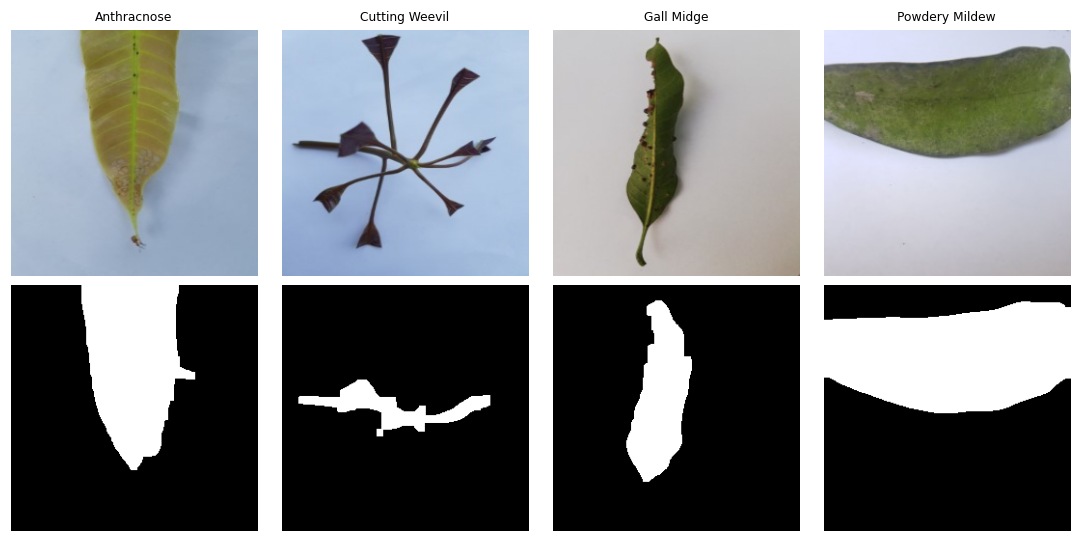

In [ ]:
def leaf_mask(img):
    """Auto-threshold per image using Otsu to separate leaf from background."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Otsu finds the best threshold to split the image into two groups
    _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # clean up small holes and noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((11, 11), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))

    # keep only the largest connected component
    n, labels, st, _ = cv2.connectedComponentsWithStats(mask)
    if n > 1:
        largest = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])
        mask = (labels == largest).astype(np.uint8)

    # if mask covers less than 5% or more than 95%, fall back to full image
    frac = mask.sum() / mask.size
    if frac < 0.05 or frac > 0.95:
        mask = np.ones(gray.shape, np.uint8)

    return mask.astype(bool)


def lesion_proxy(img, leaf):
    """Dark pixels within the leaf area as a rough lesion proxy."""
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    dark = (gray < 80) & leaf
    dark = cv2.morphologyEx(
        dark.astype(np.uint8),
        cv2.MORPH_OPEN,
        np.ones((3, 3), np.uint8),
    )
    return dark.astype(bool)


LEAF = np.stack([leaf_mask(img) for img in IMGS])
LESION = np.stack([
    lesion_proxy(img, leaf)
    for img, leaf in zip(IMGS, LEAF)
])
df["lesion_of_leaf"] = [
    LESION[i].sum() / max(LEAF[i].sum(), 1)
    for i in range(len(IMGS))
]

# show examples
fig, axs = plt.subplots(2, 4, figsize=(10, 5))
for k in range(4):
    idx = k * len(IMGS) // 4
    axs[0, k].imshow(IMGS[idx])
    axs[0, k].set_title(CLASSES[Y[idx]], fontsize=8)
    axs[1, k].imshow(LEAF[idx], cmap="gray")
    axs[0, k].axis("off")
    axs[1, k].axis("off")
axs[0, 0].set_ylabel("image")
axs[1, 0].set_ylabel("leaf mask")
plt.tight_layout()
plt.show()


### 1.2 Background colour check

Photos of one disease were often taken on the same surface.
If background colour differs by class, the model could use that as a shortcut.


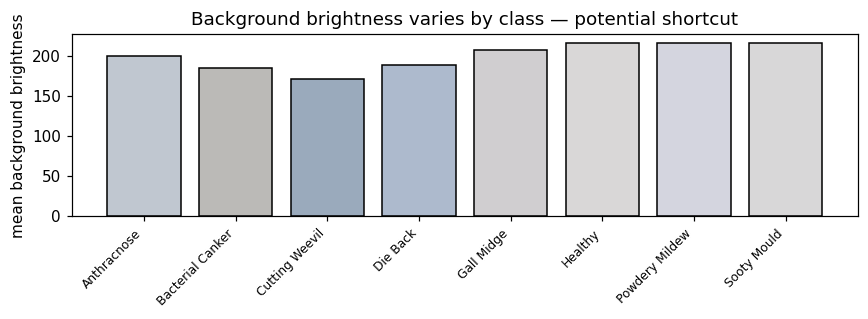

In [ ]:
# average background colour per class (pixels outside leaf mask)
bg_colors = []
for i in range(len(IMGS)):
    bg = IMGS[i][~LEAF[i]]
    bg_colors.append(bg.mean(axis=0) if len(bg) > 0 else [128, 128, 128])
bg_colors = np.array(bg_colors)

fig, ax = plt.subplots(figsize=(8, 3))
means = [bg_colors[Y == c].mean(0) for c in range(NC)]
ax.bar(
    range(NC),
    [m.mean() for m in means],
    color=[(m / 255).clip(0, 1) for m in means],
    edgecolor="black",
)
ax.set_xticks(range(NC))
ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("mean background brightness")
ax.set_title("Background brightness varies by class — potential shortcut")
plt.tight_layout()
plt.show()


---
## 2. Leakage-aware split *(feedback: copies across a random split)*

**Why it matters.** If a zoomed copy of the same leaf ends up in both train and test, the test accuracy is inflated.

**Simple fix:** group by filename timestamp (copies share the same timestamp), then use `StratifiedGroupKFold` so no group crosses splits.


In [ ]:
# group images by their timestamp key (copies share the same key)
groups_by_stem = pd.factorize(df["stem_key"])[0]
n_groups = len(np.unique(groups_by_stem))
print(f"{n_groups} unique groups from {len(df)} images")


def make_split(y, groups, seed):
    """~71% train / 14% val / 14% test, stratified, groups never split."""
    sgkf = StratifiedGroupKFold(
        n_splits=7, shuffle=True, random_state=seed,
    )
    folds = [te for _, te in sgkf.split(np.zeros(len(y)), y, groups)]
    return np.concatenate(folds[2:]), folds[1], folds[0]


# --- RQ1: how much does a naive split inflate accuracy? ---
from sklearn.model_selection import StratifiedShuffleSplit

# use small downsampled images to save RAM (64x64 instead of 256x256)
X_small = np.stack([
    cv2.resize(img, (64, 64)).ravel()
    for img in IMGS
]).astype(np.float32) / 255.0

# naive split (ignoring groups)
naive_splits = StratifiedShuffleSplit(
    n_splits=3, test_size=0.14, random_state=42,
)
naive_accs = []
for tr, te in naive_splits.split(np.zeros(len(Y)), Y):
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, C=0.05),
    )
    clf.fit(X_small[tr], Y[tr])
    naive_accs.append(accuracy_score(Y[te], clf.predict(X_small[te])))

# grouped split
idx_tr, idx_va, idx_te = make_split(Y, groups_by_stem, SPLIT_SEED)
clf_g = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, C=0.05),
)
clf_g.fit(X_small[idx_tr], Y[idx_tr])
grouped_acc = accuracy_score(Y[idx_te], clf_g.predict(X_small[idx_te]))
del X_small  # free memory

print(f"Naive split accuracy:   {np.mean(naive_accs):.3f} +/- {np.std(naive_accs):.3f}")
print(f"Grouped split accuracy: {grouped_acc:.3f}")
print(f"=> Naive split inflates accuracy by ~{100*(np.mean(naive_accs) - grouped_acc):.1f} pp")

# verify no group crosses splits
g_tr = set(groups_by_stem[idx_tr])
g_va = set(groups_by_stem[idx_va])
g_te = set(groups_by_stem[idx_te])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), \
    "group leaked!"

print("")
print(f"No group crosses splits. Sizes: train {len(idx_tr)}, val {len(idx_va)}, test {len(idx_te)}")
print(pd.crosstab(df.iloc[idx_te]["cls"], columns="count").to_string())
GROUPS = groups_by_stem

3671 unique groups from 4000 images
Naive split accuracy:   0.801 +/- 0.013
Grouped split accuracy: 0.746
=> Naive split inflates accuracy by ~5.6 pp

No group crosses splits. Sizes: train 2868, val 566, test 566
col_0             count
cls                    
Anthracnose          71
Bacterial Canker     72
Cutting Weevil       66
Die Back             70
Gall Midge           72
Healthy              73
Powdery Mildew       70
Sooty Mould          72


---
## 3. Interpretable baseline *(feedback: "inherently interpretable" depends on the features)*

Logistic regression on **27 named features** a person can read:
- **Shape (4):** leaf area fraction, aspect ratio, solidity, outline complexity
- **Colour means & spreads inside leaf (11):** L/a/b mean+std (CIELAB), H mean, S mean+std, V mean+std (HSV)
- **Colour fractions inside leaf (5):** green, yellow, brown, dark, whitish — partly collinear (roughly sum to 1), so some coefficients will be unstable; the sign-stability check flags which ones
- **Lesion proxy geometry (4):** lesion area fraction, log count, log mean size, largest blob fraction
- **Texture (3):** Laplacian log-variance, gradient magnitude, edge density

Coefficients are standardised so they are comparable.
We check **sign stability** under bootstrap and flag coefficients whose sign flips across refits.


In [ ]:
FEATURE_NAMES = [
    "leaf_area_frac", "leaf_aspect", "leaf_solidity", "leaf_outline_complexity",
    "L_mean", "L_std", "a_mean", "a_std", "b_mean", "b_std",
    "H_mean", "S_mean", "S_std", "V_mean", "V_std",
    "frac_green", "frac_yellow", "frac_brown", "frac_dark", "frac_whitish",
    "lesion_area_of_leaf", "lesion_count_log", "lesion_mean_size_log",
    "lesion_largest_of_leaf",
    "texture_laplacian_logvar", "texture_gradient_mean", "texture_edge_density",
]


def extract_features(img, leaf, lesion):
    """Extract 27 named, human-readable features from one image."""
    f = dict.fromkeys(FEATURE_NAMES, 0.0)
    n = max(int(leaf.sum()), 1)

    if n < 800:  # too little leaf detected
        return np.array([f[k] for k in FEATURE_NAMES], np.float32)

    # --- shape ---
    cnts, _ = cv2.findContours(
        leaf.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE,
    )
    c = max(cnts, key=cv2.contourArea)
    area = cv2.contourArea(c) + 1e-6
    per = cv2.arcLength(c, True)
    rw, rh = cv2.minAreaRect(c)[1]

    f["leaf_area_frac"] = n / leaf.size
    f["leaf_aspect"] = min(max(rw, rh) / (min(rw, rh) + 1e-6), 20.0)
    f["leaf_solidity"] = area / (cv2.contourArea(cv2.convexHull(c)) + 1e-6)
    f["leaf_outline_complexity"] = min(per ** 2 / (4 * np.pi * area), 50.0)

    # --- colour: CIELAB (inside leaf only) ---
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(np.float32)
    for k, ch in zip(["L", "a", "b"], range(3)):
        v = lab[:, :, ch][leaf]
        f[f"{k}_mean"] = v.mean()
        f[f"{k}_std"] = v.std()

    # --- colour: HSV (inside leaf only) ---
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    H = hsv[:, :, 0][leaf]
    S = hsv[:, :, 1][leaf]
    V = hsv[:, :, 2][leaf]

    f["H_mean"] = H.mean()
    f["S_mean"] = S.mean()
    f["S_std"] = S.std()
    f["V_mean"] = V.mean()
    f["V_std"] = V.std()

    # --- colour fractions (partly collinear) ---
    f["frac_green"]   = np.mean((H >= 35) & (H <= 85) & (S >= 50))
    f["frac_yellow"]  = np.mean((H >= 20) & (H < 35) & (S >= 60))
    f["frac_brown"]   = np.mean((H < 20) & (S >= 50))
    f["frac_dark"]    = np.mean(V < 70)
    f["frac_whitish"] = np.mean((S < 40) & (V >= 140))

    # --- lesion proxy geometry ---
    nl, _, st, _ = cv2.connectedComponentsWithStats(
        lesion.astype(np.uint8), connectivity=8,
    )
    sizes = st[1:, cv2.CC_STAT_AREA] if nl > 1 else np.array([0])
    f["lesion_area_of_leaf"] = lesion.sum() / n
    f["lesion_count_log"] = np.log1p(nl - 1)
    f["lesion_mean_size_log"] = np.log1p(sizes.mean())
    f["lesion_largest_of_leaf"] = sizes.max() / n

    # --- texture (inside eroded leaf core to avoid edge artefacts) ---
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    core = cv2.erode(
        leaf.astype(np.uint8), np.ones((7, 7), np.uint8),
    ).astype(bool)
    if core.sum() > 100:
        lap = cv2.Laplacian(gray, cv2.CV_32F)
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)
        f["texture_laplacian_logvar"] = np.log1p(lap[core].var())
        f["texture_gradient_mean"] = np.sqrt(gx ** 2 + gy ** 2)[core].mean()
        f["texture_edge_density"] = (cv2.Canny(gray, 50, 150) > 0)[core].mean()

    return np.array([f[k] for k in FEATURE_NAMES], np.float32)


X_HC = np.stack([
    extract_features(IMGS[i], LEAF[i], LESION[i])
    for i in range(len(IMGS))
])
print(f"Feature matrix: {X_HC.shape} -- {len(FEATURE_NAMES)} features")

# fit with regularisation search on val set
best_f1, best_C, best_pen = 0, 1.0, "l2"
for pen in ["l2", "l1"]:
    for C in [0.03, 0.1, 0.3, 1, 3]:
        solver = "lbfgs" if pen == "l2" else "saga"
        m = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C, penalty=pen, solver=solver,
                max_iter=4000, class_weight="balanced",
            ),
        )
        m.fit(X_HC[idx_tr], Y[idx_tr])
        f1 = f1_score(Y[idx_va], m.predict(X_HC[idx_va]), average="macro")
        if f1 > best_f1:
            best_f1, best_C, best_pen = f1, C, pen

print(f"Best: penalty={best_pen}, C={best_C}, val macro-F1={best_f1:.3f}")

solver = "lbfgs" if best_pen == "l2" else "saga"
LR_HC = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=best_C, penalty=best_pen, solver=solver,
        max_iter=4000, class_weight="balanced",
    ),
)
LR_HC.fit(X_HC[idx_tr], Y[idx_tr])
P_lr = LR_HC.predict_proba(X_HC)

acc_lr = accuracy_score(Y[idx_te], P_lr[idx_te].argmax(1))
f1_lr = f1_score(Y[idx_te], P_lr[idx_te].argmax(1), average="macro")
print(f"Interpretable LR -- test acc {acc_lr:.3f} | macro-F1 {f1_lr:.3f}")


Feature matrix: (4000, 27) -- 27 features
Best: penalty=l1, C=3, val macro-F1=0.951
Interpretable LR -- test acc 0.951 | macro-F1 0.951


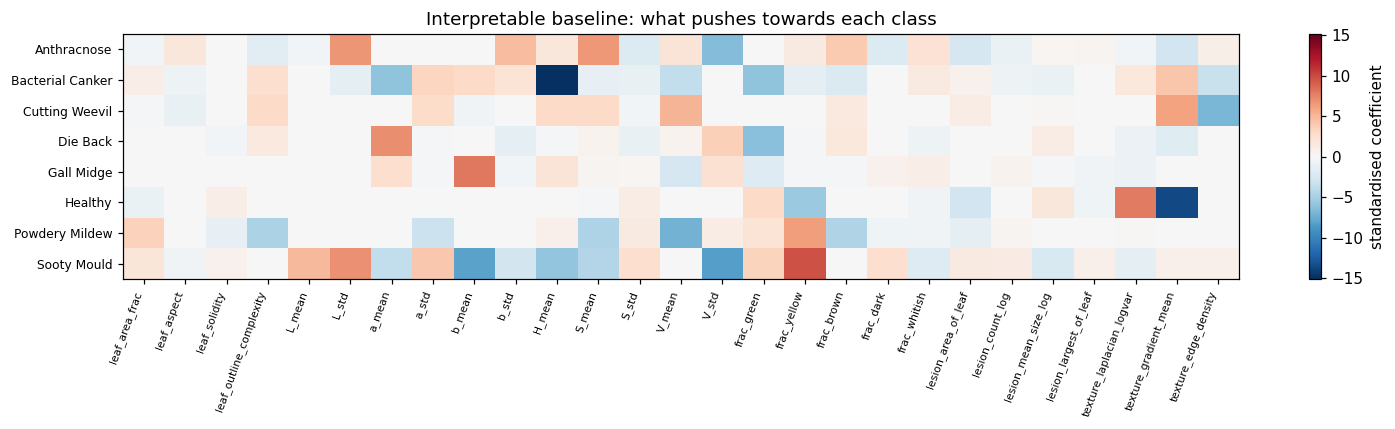

Anthracnose      -- L_std (+6.61), V_std (-6.51), S_mean (+6.50), b_std (+4.65)
Bacterial Canker -- H_mean (-15.10), frac_green (-6.03), a_mean (-6.03), texture_gradient_mean (+4.17)
Cutting Weevil   -- texture_edge_density (-6.93), texture_gradient_mean (+6.06), V_mean (+5.09), leaf_outline_complexity (+2.93)
Die Back         -- a_mean (+7.06), frac_green (-6.33), V_std (+3.64), texture_gradient_mean (-1.84)
Gall Midge       -- b_mean (+8.00), a_mean (+2.57), V_mean (-2.56), V_std (+2.30)
Healthy          -- texture_gradient_mean (-13.63), texture_laplacian_logvar (+7.88), frac_yellow (-5.62), frac_green (+2.90)
Powdery Mildew   -- V_mean (-7.18), frac_yellow (+6.34), leaf_outline_complexity (-4.79), S_mean (-4.67)
Sooty Mould      -- frac_yellow (+9.59), V_std (-8.35), b_mean (-8.08), L_std (+6.89)

Sign stability of top-quartile coefficients: median 1.00
Share with stability >= 0.9: 100%
Large-but-unstable coefficients (interpret with care): []


In [ ]:
 # ----- Can a person read the coefficients? -----

coef = np.zeros((NC, len(FEATURE_NAMES)))
coef[LR_HC[-1].classes_] = LR_HC[-1].coef_
coef_df = pd.DataFrame(coef, index=CLASSES, columns=FEATURE_NAMES)

# heatmap
fig, ax = plt.subplots(figsize=(14, 4))
vmax = np.abs(coef).max()
im = ax.imshow(coef, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(FEATURE_NAMES)))
ax.set_xticklabels(FEATURE_NAMES, rotation=70, ha="right", fontsize=7)
ax.set_yticks(range(NC))
ax.set_yticklabels(CLASSES, fontsize=8)
plt.colorbar(im, label="standardised coefficient")
plt.title("Interpretable baseline: what pushes towards each class")
plt.tight_layout()
plt.show()

# top 4 features per class
for c in CLASSES:
    s = coef_df.loc[c].sort_values(key=np.abs, ascending=False).head(4)
    print(f"{c:16s} -- " + ", ".join(f"{k} ({v:+.2f})" for k, v in s.items()))

# sign stability under group bootstrap
rng = np.random.default_rng(0)
ug = np.unique(GROUPS[idx_tr])
signs = []

for _ in range(50):
    gs = rng.choice(ug, len(ug), replace=True)
    ids = np.concatenate([idx_tr[GROUPS[idx_tr] == g] for g in gs])
    solver_b = "lbfgs" if best_pen == "l2" else "saga"
    mb = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=best_C, penalty=best_pen, solver=solver_b,
            max_iter=4000, class_weight="balanced",
        ),
    )
    mb.fit(X_HC[ids], Y[ids])
    cb = np.zeros_like(coef)
    cb[mb[-1].classes_] = mb[-1].coef_
    signs.append(np.sign(cb))

stab = np.abs(np.mean(signs, 0))
top_mask = np.abs(coef) >= np.percentile(np.abs(coef), 75)

print(f"\nSign stability of top-quartile coefficients: median {np.median(stab[top_mask]):.2f}")
print(f"Share with stability >= 0.9: {(stab[top_mask] >= 0.9).mean():.0%}")

# flag large-but-unstable coefficients
unstable = [
    (CLASSES[i], FEATURE_NAMES[j])
    for i, j in zip(*np.where(top_mask & (stab < 0.7)))
]
print(f"Large-but-unstable coefficients (interpret with care): {unstable[:12]}")

# flag framing artefacts
FRAMING = ["leaf_area_frac"]
flag = [
    (c, feat)
    for c in CLASSES
    for feat in coef_df.loc[c].abs().sort_values(ascending=False).head(4).index
    if feat in FRAMING
]
if flag:
    print(f"Top-4 coefficients encoding photo framing rather than symptoms: {flag}")


---
## 4. ResNet-50: fine-tuning and classification

ImageNet-pretrained ResNet-50, fine-tuned with lower backbone LR.
Multiple seeds for stability analysis (§9).


In [ ]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prep(batch_u8):
    """Convert uint8 numpy images to normalised float tensor."""
    x = torch.from_numpy(
        np.ascontiguousarray(batch_u8)
    ).permute(0, 3, 1, 2).float() / 255.0
    return (x - MEAN) / STD


def make_model():
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(2048, NC)
    return m


@torch.no_grad()
def predict(model, imgs, bs=64, return_feats=False):
    """Run inference on a numpy array of images."""
    model.eval()
    logits_all, feats_all = [], []
    for i in range(0, len(imgs), bs):
        x = prep(imgs[i:i + bs]).to(DEVICE)
        x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
        x = model.layer4(model.layer3(model.layer2(model.layer1(x))))
        feat = torch.flatten(model.avgpool(x), 1)
        logit = model.fc(feat)
        logits_all.append(logit.cpu().numpy())
        feats_all.append(feat.cpu().numpy())
    L = np.concatenate(logits_all)
    return (L, np.concatenate(feats_all)) if return_feats else L


def softmax(L, T=1.0):
    z = L / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(0.25, 0.2, 0.15),
])


class TrainDS(Dataset):
    def __init__(self, idx):
        self.idx = idx

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        x = train_tf(torch.from_numpy(IMGS[j]).permute(2, 0, 1))
        return (x.float() / 255 - MEAN[0]) / STD[0], int(Y[j])


def train_resnet(seed):
    """Fine-tune ResNet-50 with a given seed."""
    ck = OUT / "ckpt" / f"resnet50_seed{seed}.pt"
    model = make_model().to(DEVICE)

    if REUSE_CKPT and ck.exists():
        model.load_state_dict(torch.load(ck, map_location=DEVICE))
        print(f"seed {seed}: loaded checkpoint")
        return model.eval()

    set_seed(seed)
    dl = DataLoader(
        TrainDS(idx_tr), batch_size=BATCH,
        shuffle=True, drop_last=len(idx_tr) > BATCH,
    )
    head = list(model.fc.parameters())
    body = [p for n, p in model.named_parameters() if not n.startswith("fc.")]
    opt = torch.optim.AdamW(
        [{"params": body, "lr": LR_BACK},
         {"params": head, "lr": LR_HEAD}],
        weight_decay=1e-4,
    )
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=[LR_BACK, LR_HEAD],
        total_steps=EPOCHS * len(dl), pct_start=0.15,
    )
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    best_f1, best_sd = -1, None

    for ep in range(EPOCHS):
        model.train()
        t0 = time.time()
        for x, y in dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            sched.step()

        pv = predict(model, IMGS[idx_va]).argmax(1)
        f1 = f1_score(Y[idx_va], pv, average="macro")
        print(f"  seed {seed} ep {ep+1}/{EPOCHS} val-F1 {f1:.3f} ({time.time()-t0:.0f}s)")
        if f1 > best_f1:
            best_f1 = f1
            best_sd = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_sd)
    torch.save(best_sd, ck)
    return model.eval()


MODELS = {s: train_resnet(s) for s in SEEDS}
model = MODELS[SEEDS[0]]


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


seed 0: loaded checkpoint
seed 1: loaded checkpoint
seed 2: loaded checkpoint


Temperature T = 0.200
           model  test_acc  test_macroF1
Interpretable LR    0.9505        0.9508
ResNet-50 seed 0    0.9982        0.9982
ResNet-50 seed 1    1.0000        1.0000
ResNet-50 seed 2    0.9982        0.9983

Per-class (seed 0):
                  precision  recall     F1  support
Anthracnose           1.000   0.986  0.993       71
Bacterial Canker      1.000   1.000  1.000       72
Cutting Weevil        0.985   1.000  0.992       66
Die Back              1.000   1.000  1.000       70
Gall Midge            1.000   1.000  1.000       72
Healthy               1.000   1.000  1.000       73
Powdery Mildew        1.000   1.000  1.000       70
Sooty Mould           1.000   1.000  1.000       72


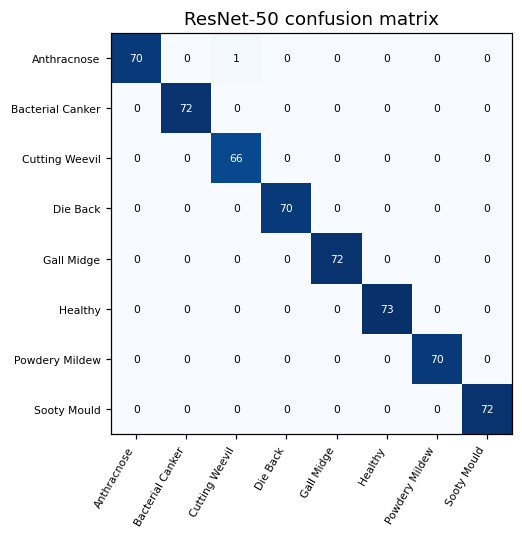

In [ ]:
# ----- Predictions and comparison -----

LOGITS, FEATS = {}, {}
for s, mdl in MODELS.items():
    LOGITS[s], FEATS[s] = predict(mdl, IMGS, return_feats=True)
L0, F0 = LOGITS[SEEDS[0]], FEATS[SEEDS[0]]

# temperature scaling on validation logits
grid = np.exp(np.linspace(np.log(0.2), np.log(10), 80))
nll = [
    -np.log(
        softmax(L0[idx_va], T)[np.arange(len(idx_va)), Y[idx_va]] + 1e-12
    ).mean()
    for T in grid
]
TEMP = float(grid[int(np.argmin(nll))])
P0 = softmax(L0, TEMP)
print(f"Temperature T = {TEMP:.3f}")

# comparison table
mf1 = lambda y, p: f1_score(y, p, average="macro", labels=range(NC))
yt = Y[idx_te]

rows = [
    ("Interpretable LR",
     accuracy_score(yt, P_lr[idx_te].argmax(1)),
     mf1(yt, P_lr[idx_te].argmax(1))),
]
for s in SEEDS:
    pr = LOGITS[s][idx_te].argmax(1)
    rows.append((f"ResNet-50 seed {s}", accuracy_score(yt, pr), mf1(yt, pr)))

cmp_df = pd.DataFrame(rows, columns=["model", "test_acc", "test_macroF1"])
print(cmp_df.round(4).to_string(index=False))

# per-class report
pr0 = L0[idx_te].argmax(1)
p, r, f, sup = precision_recall_fscore_support(
    yt, pr0, labels=range(NC), zero_division=0,
)
print("\nPer-class (seed 0):")
print(
    pd.DataFrame(
        {"precision": p, "recall": r, "F1": f, "support": sup},
        index=CLASSES,
    ).round(3).to_string()
)

# confusion matrix
cm = confusion_matrix(yt, pr0, labels=range(NC))
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NC))
ax.set_yticks(range(NC))
ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=7)
ax.set_yticklabels(CLASSES, fontsize=7)
for i in range(NC):
    for j in range(NC):
        ax.text(
            j, i, cm[i, j], ha="center", va="center",
            fontsize=7, color="w" if cm[i, j] > cm.max() / 2 else "k",
        )
ax.set_title("ResNet-50 confusion matrix")
plt.tight_layout()
plt.show()


---
## 5. Triage-aware evaluation *(feedback: which mistakes hurt the officer most?)*

Missing a High-priority disease is worse than confusing two Low-priority ones.
We evaluate at the **tier level**.


Missed-high rate:  0.004 (true High predicted below High)
False-alarm rate:  0.000 (not-High predicted as High)
Cross-tier errors: 0.002
Overall accuracy:  0.998


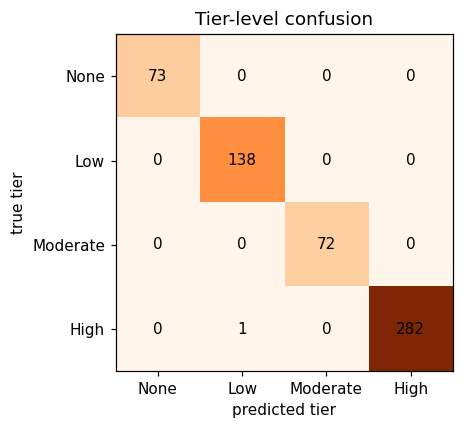


Total errors: 1 | within-tier: 0 | cross-tier: 1
true         pred          
Anthracnose  Cutting Weevil    1


In [ ]:
TRIAGE = {
    "Anthracnose": "High", "Bacterial Canker": "High",
    "Die Back": "High", "Powdery Mildew": "High",
    "Gall Midge": "Moderate",
    "Sooty Mould": "Low", "Cutting Weevil": "Low",
    "Healthy": "None",
}
TIER_NUM = {"None": 0, "Low": 1, "Moderate": 2, "High": 3}
TIER_NAMES = ["None", "Low", "Moderate", "High"]


def tier_vec():
    return np.array([TIER_NUM[TRIAGE[c]] for c in CLASSES])


tv = tier_vec()
pred = P0[idx_te].argmax(1)
tier_true = tv[yt]
tier_pred = tv[pred]

# key metrics
hi = tier_true == 3
missed_high = (tier_pred[hi] < 3).mean() if hi.any() else 0
false_alarm = ((tier_pred == 3) & (tier_true < 3)).mean()
cross_tier = (tier_true != tier_pred).mean()

print(f"Missed-high rate:  {missed_high:.3f} (true High predicted below High)")
print(f"False-alarm rate:  {false_alarm:.3f} (not-High predicted as High)")
print(f"Cross-tier errors: {cross_tier:.3f}")
print(f"Overall accuracy:  {(pred == yt).mean():.3f}")

# tier confusion matrix
cm_tier = confusion_matrix(tier_true, tier_pred, labels=range(4))
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm_tier, cmap="Oranges")
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set_xticklabels(TIER_NAMES)
ax.set_yticklabels(TIER_NAMES)
ax.set_xlabel("predicted tier")
ax.set_ylabel("true tier")
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm_tier[i, j], ha="center", va="center")
ax.set_title("Tier-level confusion")
plt.tight_layout()
plt.show()

# which cross-tier errors?
err = pd.DataFrame({
    "true": np.array(CLASSES)[yt],
    "pred": np.array(CLASSES)[pred],
})
err = err[err.true != err.pred]
err["cross_tier"] = [
    tv[CLASSES.index(a)] != tv[CLASSES.index(b)]
    for a, b in zip(err.true, err.pred)
]
n_within = (~err.cross_tier).sum()
n_cross = err.cross_tier.sum()
print(f"\nTotal errors: {len(err)} | within-tier: {n_within} | cross-tier: {n_cross}")
if n_cross > 0:
    print(err[err.cross_tier].value_counts(["true", "pred"]).head(5).to_string())


---
## 6. Grad-CAM explanations

Using the `pytorch-grad-cam` library for clean, tested implementation.
We also define **null explainers** (no model information) to give each metric a baseline.


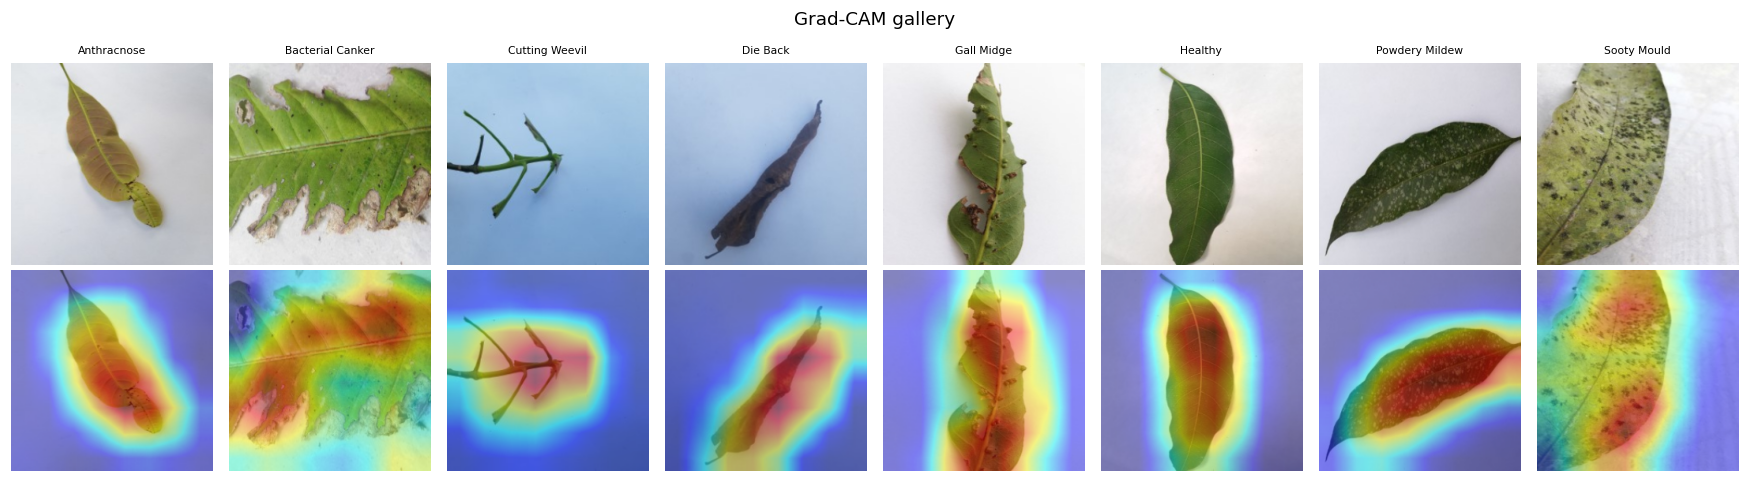

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


def get_gradcam_maps(model, imgs, targets=None, bs=32):
    """Get Grad-CAM heatmaps for a batch of images."""
    target_layer = model.layer4[-1]
    maps = []

    for i in range(0, len(imgs), bs):
        batch = imgs[i:i + bs]
        input_tensor = prep(batch).to(DEVICE)

        if targets is not None:
            tgts = [
                [ClassifierOutputTarget(int(t))]
                for t in targets[i:i + bs]
            ]
        else:
            with torch.no_grad():
                preds = model(input_tensor).argmax(1).cpu().numpy()
            tgts = [[ClassifierOutputTarget(int(p))] for p in preds]

        with GradCAM(model=model, target_layers=[target_layer]) as cam:
            for j in range(len(batch)):
                grayscale_cam = cam(
                    input_tensor=input_tensor[j:j + 1],
                    targets=tgts[j],
                )
                maps.append(grayscale_cam[0])

    return np.stack(maps)


# ----- null explainers -----

yy, xx = np.mgrid[:IMG, :IMG]
CENTER_MAP = np.exp(
    -(((yy - IMG / 2) / (0.28 * IMG)) ** 2
      + ((xx - IMG / 2) / (0.28 * IMG)) ** 2) / 2
).astype(np.float32)
CENTER_MAP = (CENTER_MAP - CENTER_MAP.min()) / (CENTER_MAP.max() - CENTER_MAP.min())


def null_random(rng):
    m = cv2.resize(
        rng.random((8, 8)).astype(np.float32),
        (IMG, IMG), interpolation=cv2.INTER_CUBIC,
    )
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def null_edge(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    m = np.hypot(
        cv2.Sobel(g, cv2.CV_32F, 1, 0),
        cv2.Sobel(g, cv2.CV_32F, 0, 1),
    )
    m = cv2.GaussianBlur(m, (0, 0), 6)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def null_leaf(leaf):
    m = cv2.GaussianBlur(leaf.astype(np.float32), (0, 0), 6)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)


def overlay(img, cam, alpha=0.45):
    h = cv2.applyColorMap(
        (255 * cam).astype(np.uint8), cv2.COLORMAP_JET,
    )[..., ::-1]
    return (img * (1 - alpha) + h * alpha).astype(np.uint8)


# ----- gallery -----
rng = np.random.default_rng(3)
show_idx = []
for c in range(NC):
    ok = [i for i in idx_te if Y[i] == c and L0[i].argmax() == c]
    if ok:
        show_idx.append(rng.choice(ok))
show_idx = np.array(show_idx)
show_cams = get_gradcam_maps(model, IMGS[show_idx])

fig, axs = plt.subplots(2, len(show_idx), figsize=(2 * len(show_idx), 4.5))
for k, i in enumerate(show_idx):
    axs[0, k].imshow(IMGS[i])
    axs[1, k].imshow(overlay(IMGS[i], show_cams[k]))
    axs[0, k].set_title(CLASSES[Y[i]], fontsize=7)
    axs[0, k].axis("off")
    axs[1, k].axis("off")
plt.suptitle("Grad-CAM gallery")
plt.tight_layout()
plt.show()


---
## 7. Plausibility: do heat maps land on lesions?

Plausibility = "the explanation looks right." Necessary but not sufficient (§8 tests if the model *uses* those regions).

Metrics (on dark-spot disease classes where the proxy is valid):
- **Lesion enrichment**: CAM mass on lesion / expected if uniform on leaf. >1 = concentrated on lesions.
- **Pointing-game hit**: CAM maximum falls inside the lesion.


Localisation set: 208 images
                 enrichment  pointing_hit
Grad-CAM              1.089         0.394
null: random          1.013         0.058
null: center          1.026         0.312
null: edge            1.326         0.534
null: leaf mask       1.009         0.361


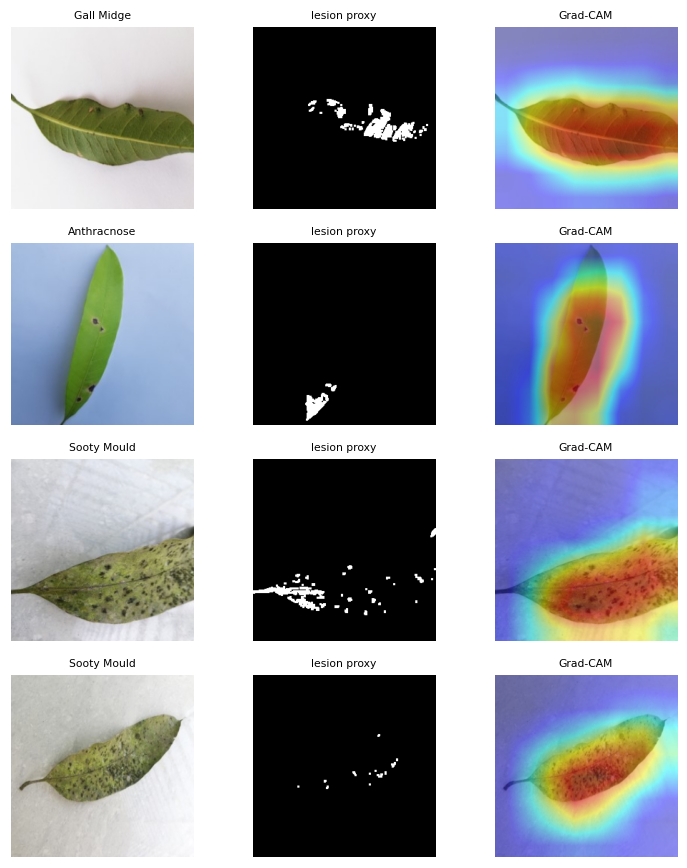

In [ ]:
LOC_CLASSES = ["Anthracnose", "Bacterial Canker", "Gall Midge", "Sooty Mould"]


def loc_metrics(cam, leaf, target):
    """Plausibility metrics for one image."""
    leaf_m = cam[leaf].sum() + 1e-8
    tgt_in = cam[target & leaf].sum()
    area_t = (target & leaf).sum()
    area_l = leaf.sum() + 1e-8
    enrich = (tgt_in / leaf_m) / (area_t / area_l + 1e-8)

    tol = cv2.dilate(
        target.astype(np.uint8), np.ones((9, 9), np.uint8),
    ).astype(bool)
    hit = tol[np.unravel_index(cam.argmax(), cam.shape)]
    return dict(enrichment=enrich, pointing_hit=float(hit))


loc_idx = np.array([
    i for i in idx_te
    if CLASSES[Y[i]] in LOC_CLASSES
    and L0[i].argmax() == Y[i]
    and 0.01 <= df.lesion_of_leaf.iloc[i] <= 0.6
])
print(f"Localisation set: {len(loc_idx)} images")

if len(loc_idx) >= 3:
    cams_loc = get_gradcam_maps(model, IMGS[loc_idx])
    rng_loc = np.random.default_rng(0)

    methods = {
        "Grad-CAM": cams_loc,
        "null: random": np.stack([null_random(rng_loc) for _ in loc_idx]),
        "null: center": np.stack([CENTER_MAP] * len(loc_idx)),
        "null: edge": np.stack([null_edge(IMGS[i]) for i in loc_idx]),
        "null: leaf mask": np.stack([null_leaf(LEAF[i]) for i in loc_idx]),
    }

    rows = {}
    for name, M in methods.items():
        metrics = [
            loc_metrics(M[k], LEAF[i], LESION[i])
            for k, i in enumerate(loc_idx)
        ]
        rows[name] = pd.DataFrame(metrics).mean()
    print(pd.DataFrame(rows).T.round(3).to_string())

    # qualitative panel
    pick = np.random.default_rng(5).choice(
        len(loc_idx), min(4, len(loc_idx)), replace=False,
    )
    fig, axs = plt.subplots(len(pick), 3, figsize=(7, 2 * len(pick)))
    for r, k in enumerate(pick):
        i = loc_idx[k]
        axs[r, 0].imshow(IMGS[i])
        axs[r, 0].set_title(CLASSES[Y[i]], fontsize=7)
        axs[r, 1].imshow(LESION[i], cmap="gray")
        axs[r, 1].set_title("lesion proxy", fontsize=7)
        axs[r, 2].imshow(overlay(IMGS[i], cams_loc[k]))
        axs[r, 2].set_title("Grad-CAM", fontsize=7)
        for c in range(3):
            axs[r, c].axis("off")
    plt.tight_layout()
    plt.show()


---
## 8. Faithfulness: does the model actually *use* the highlighted region?

**Deletion/insertion curves** (Petsiuk et al.): rank pixels by saliency, progressively remove (deletion) or reveal (insertion) them.
A faithful map makes probability **drop fast** on deletion (low AUC) and **rise fast** on insertion (high AUC).


          deletion_AUC  insertion_AUC  gap (ins - del)
Grad-CAM         0.382          0.821            0.440
random           0.610          0.599           -0.011
center           0.471          0.785            0.314
edge             0.373          0.758            0.385
leaf             0.396          0.796            0.400


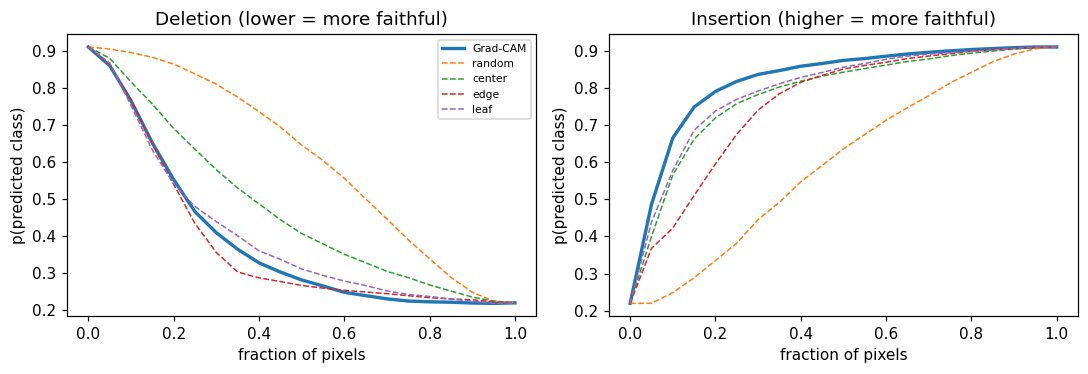

In [ ]:
STEPS = np.linspace(0, 1, 11 if QUICK_MODE else 21)


@torch.no_grad()
def prob_for_class(model, imgs_u8, cls, bs=32):
    """Get predicted probability for a specific class."""
    model.eval()
    out = []
    for k in range(0, len(imgs_u8), bs):
        x = prep(imgs_u8[k:k + bs]).to(DEVICE)
        x = model.maxpool(model.relu(model.bn1(model.conv1(x))))
        x = model.layer4(model.layer3(model.layer2(model.layer1(x))))
        logit = model.fc(torch.flatten(model.avgpool(x), 1))
        out.append(F.softmax(logit.float(), 1)[:, cls].cpu().numpy())
    return np.concatenate(out)


def del_ins_curves(model, i, cam, cls):
    """Deletion and insertion curves for one image."""
    order = np.argsort(-cam, axis=None)
    rank = np.empty_like(order)
    rank[order] = np.arange(order.size)
    rank = rank.reshape(cam.shape)

    base = cv2.GaussianBlur(IMGS[i], (0, 0), 14)
    dels, inss = [], []

    for frac in STEPS:
        m = (rank < frac * rank.size)[..., None]
        dels.append(np.where(m, base, IMGS[i]))
        inss.append(np.where(m, IMGS[i], base))

    probs = prob_for_class(model, np.stack(dels + inss), cls)
    return probs[:len(STEPS)], probs[len(STEPS):]


# select correctly classified test images
faith_idx = np.array([i for i in idx_te if L0[i].argmax() == Y[i]])
faith_idx = np.random.default_rng(7).choice(
    faith_idx, min(N_FAITH, len(faith_idx)), replace=False,
)

# get maps for all methods
cams_faith = get_gradcam_maps(model, IMGS[faith_idx])
rng_f = np.random.default_rng(0)

all_maps = {
    "Grad-CAM": cams_faith,
    "random": np.stack([null_random(rng_f) for _ in faith_idx]),
    "center": np.stack([CENTER_MAP] * len(faith_idx)),
    "edge": np.stack([null_edge(IMGS[i]) for i in faith_idx]),
    "leaf": np.stack([null_leaf(LEAF[i]) for i in faith_idx]),
}

# run deletion/insertion
DEL = {m: [] for m in all_maps}
INS = {m: [] for m in all_maps}
cls_f = L0[faith_idx].argmax(1)

for k, i in enumerate(faith_idx):
    for m, M in all_maps.items():
        d, n = del_ins_curves(model, i, M[k], cls_f[k])
        DEL[m].append(d)
        INS[m].append(n)

DEL = {m: np.array(v) for m, v in DEL.items()}
INS = {m: np.array(v) for m, v in INS.items()}

_trapz = getattr(np, "trapezoid", None) or np.trapz
auc_fn = lambda C: _trapz(C, STEPS, axis=1)

fa = pd.DataFrame({
    m: {
        "deletion_AUC": auc_fn(DEL[m]).mean(),
        "insertion_AUC": auc_fn(INS[m]).mean(),
    }
    for m in all_maps
}).T
fa["gap (ins - del)"] = fa.insertion_AUC - fa.deletion_AUC
print(fa.round(3).to_string())

# plot
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for m in all_maps:
    lw = 2.2 if m == "Grad-CAM" else 1
    ls = "-" if m == "Grad-CAM" else "--"
    ax[0].plot(STEPS, DEL[m].mean(0), label=m, lw=lw, ls=ls)
    ax[1].plot(STEPS, INS[m].mean(0), label=m, lw=lw, ls=ls)
ax[0].set_title("Deletion (lower = more faithful)")
ax[1].set_title("Insertion (higher = more faithful)")
for a in ax:
    a.set_xlabel("fraction of pixels")
    a.set_ylabel("p(predicted class)")
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.show()


### 8.2 Sanity check: cascading randomisation (Adebayo et al.)

Progressively randomise network weights from top to bottom.
A faithful explanation must **change** — if it doesn't, it just reflects image structure.


             state  correlation with original
           trained                      1.000
    + randomise fc                      0.065
+ randomise layer4                      0.208
+ randomise layer3                      0.019
+ randomise layer2                      0.320
+ randomise layer1                      0.278
 + randomise conv1                      0.221


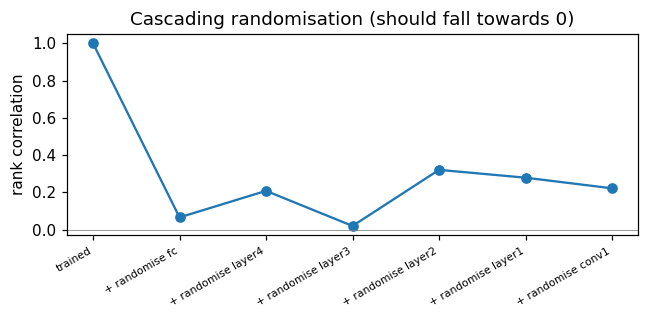

In [ ]:
def small(M, s=32):
    """Downsample maps to 32x32 and flatten for correlation."""
    return np.stack([
        cv2.resize(m, (s, s), interpolation=cv2.INTER_AREA)
        for m in M
    ]).reshape(len(M), -1)


def mean_spearman(A, B):
    return np.nanmean([stats.spearmanr(a, b)[0] for a, b in zip(A, B)])


sub = faith_idx[:min(len(faith_idx), 40)]
ref_maps = get_gradcam_maps(model, IMGS[sub], targets=L0[sub].argmax(1))

# progressively randomise layers
order = ["fc", "layer4", "layer3", "layer2", "layer1", "conv1"]
rnd_model = copy.deepcopy(model)
curve = [("trained", 1.0)]
torch.manual_seed(123)

for name in order:
    mod = getattr(rnd_model, name)
    for m in mod.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    cur_maps = get_gradcam_maps(
        rnd_model, IMGS[sub], targets=L0[sub].argmax(1),
    )
    corr = mean_spearman(small(ref_maps), small(cur_maps))
    curve.append((f"+ randomise {name}", corr))

sc = pd.DataFrame(curve, columns=["state", "correlation with original"])
print(sc.round(3).to_string(index=False))

plt.figure(figsize=(6, 3))
plt.plot(range(len(sc)), sc.iloc[:, 1], "o-")
plt.xticks(range(len(sc)), sc.state, rotation=30, ha="right", fontsize=7)
plt.axhline(0, c="gray", lw=0.5)
plt.ylabel("rank correlation")
plt.title("Cascading randomisation (should fall towards 0)")
plt.tight_layout()
plt.show()


---
## 9. Stability *(feedback: stable across repeated runs / small input changes)*

**9.1 Across retraining:** same images, different seeds.
**9.2 Across perturbations:** noise, brightness, shift, JPEG.


In [ ]:
def top_iou(A, B, p=0.2):
    """IoU of the top-p% pixels between two sets of maps."""
    r = []
    for a, b in zip(A, B):
        k = int(p * a.size)
        ta = np.zeros(a.size, bool)
        ta[np.argsort(-a.ravel())[:k]] = True
        tb = np.zeros(b.size, bool)
        tb[np.argsort(-b.ravel())[:k]] = True
        r.append((ta & tb).sum() / ((ta | tb).sum() + 1e-8))
    return np.mean(r)


sub = faith_idx[:min(len(faith_idx), 60)]

# 9.1 across seeds
seed_maps = {s: get_gradcam_maps(MODELS[s], IMGS[sub]) for s in SEEDS}
pairs = list(itertools.combinations(SEEDS, 2))

sp = [mean_spearman(small(seed_maps[a]), small(seed_maps[b]))
      for a, b in pairs]
io = [top_iou(seed_maps[a], seed_maps[b])
      for a, b in pairs]
sh = [mean_spearman(
          small(seed_maps[a]),
          small(np.roll(seed_maps[b], 1, axis=0)),
      ) for a, b in pairs]

print(f"Across seeds:")
print(f"  Spearman:      {np.mean(sp):.3f}")
print(f"  top-20%% IoU:   {np.mean(io):.3f}")
print(f"  shuffled ctrl: {np.mean(sh):.3f}")


# 9.2 perturbations
def perturb(img, kind, rng):
    if kind == "noise":
        return np.clip(
            img.astype(np.float32) + rng.normal(0, 8, img.shape),
            0, 255,
        ).astype(np.uint8)
    if kind == "bright+":
        return np.clip(
            img.astype(np.float32) * 1.1, 0, 255,
        ).astype(np.uint8)
    if kind == "shift":
        return cv2.warpAffine(
            img, np.float32([[1, 0, 8], [0, 1, 8]]),
            (IMG, IMG), borderMode=cv2.BORDER_REPLICATE,
        )
    if kind == "jpeg60":
        enc = cv2.imencode(
            ".jpg", img[:, :, ::-1],
            [cv2.IMWRITE_JPEG_QUALITY, 60],
        )[1]
        return cv2.imdecode(enc, 1)[:, :, ::-1].copy()


ref = seed_maps[SEEDS[0]]
rng_p = np.random.default_rng(21)
rows = []

for kind in ["noise", "bright+", "shift", "jpeg60"]:
    pert = np.stack([perturb(IMGS[i], kind, rng_p) for i in sub])
    pert_cams = get_gradcam_maps(model, pert)
    pert_pred = predict(model, pert).argmax(1)
    keep = pert_pred == L0[sub].argmax(1)

    if keep.sum() > 2:
        rows.append((
            kind,
            mean_spearman(small(ref[keep]), small(pert_cams[keep])),
            top_iou(ref[keep], pert_cams[keep]),
            1 - keep.mean(),
        ))

st_pert = pd.DataFrame(
    rows,
    columns=["perturbation", "Spearman", "top-20%% IoU", "label flip rate"],
)
print("\n" + st_pert.round(3).to_string(index=False))


Across seeds:
  Spearman:      0.921
  top-20%% IoU:   0.639
  shuffled ctrl: 0.518

perturbation  Spearman  top-20%% IoU  label flip rate
       noise     0.955         0.789              0.0
     bright+     0.993         0.938              0.0
       shift     0.957         0.753              0.0
      jpeg60     0.971         0.824              0.0


---
## 10. Shortcuts and field shift *(feedback: Bangladesh, one clean leaf != farmer photos)*

**10.1 Background reliance:** swap backgrounds to test if the model uses them.
**10.2 Simulated field conditions:** blur, low light, JPEG compression.


Background reliance:
                       acc  macroF1  missed_high
original             0.998    0.998        0.004
leaf only (grey bg)  0.940    0.940        0.106

Field shift stress test:
             acc  macroF1  missed_high
clean      0.998    0.998        0.004
blur       0.979    0.979        0.007
low light  0.986    0.986        0.014
jpeg q=20  0.989    0.989        0.004
combined   0.903    0.906        0.064


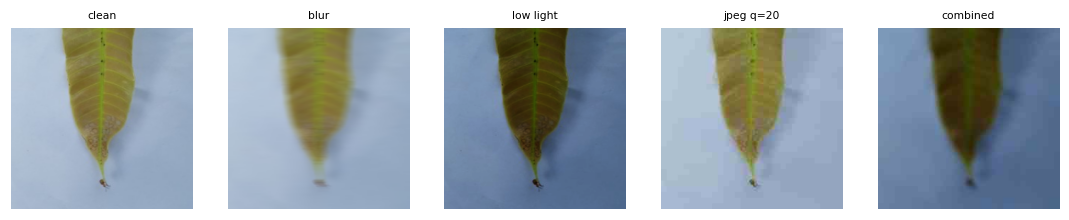

In [ ]:
def with_background(i, bg_rgb):
    """Replace background of image i with a solid colour."""
    out = IMGS[i].copy()
    m = ~cv2.dilate(
        LEAF[i].astype(np.uint8), np.ones((5, 5), np.uint8),
    ).astype(bool)
    out[m] = np.uint8(bg_rgb)
    return out


def eval_variant(imgs_u8, idx):
    """Evaluate accuracy and missed-high rate."""
    L = predict(model, imgs_u8)
    pred_v = L.argmax(1)
    y = Y[idx]
    hi = tv[y] == 3
    tp = tv[pred_v]
    missed = (tp[hi] < 3).mean() if hi.any() else 0
    return {
        "acc": (pred_v == y).mean(),
        "macroF1": mf1(y, pred_v),
        "missed_high": missed,
    }


te = idx_te

# 10.1 background test
v_gray = np.stack([with_background(i, [128, 128, 128]) for i in te])
res = {
    "original": eval_variant(IMGS[te], te),
    "leaf only (grey bg)": eval_variant(v_gray, te),
}
print("Background reliance:")
print(pd.DataFrame(res).T.round(3).to_string())


# 10.2 simulated field conditions
def field_transform(i, kind, rng):
    img = IMGS[i]
    if kind == "blur":
        k = int(rng.choice([9, 15]))
        K = np.zeros((k, k), np.float32)
        K[k // 2] = 1.0 / k
        return cv2.filter2D(img, -1, K)

    if kind == "low light":
        g = rng.uniform(1.6, 2.4)
        return np.clip(
            255 * (img / 255.0) ** g, 0, 255,
        ).astype(np.uint8)

    if kind == "jpeg q=20":
        enc = cv2.imencode(
            ".jpg", img[:, :, ::-1],
            [cv2.IMWRITE_JPEG_QUALITY, 20],
        )[1]
        return cv2.imdecode(enc, 1)[:, :, ::-1].copy()

    if kind == "combined":
        out = field_transform(i, "low light", rng)
        out = cv2.filter2D(out, -1, np.ones((9, 9), np.float32) / 81)
        enc = cv2.imencode(
            ".jpg", out[:, :, ::-1],
            [cv2.IMWRITE_JPEG_QUALITY, 30],
        )[1]
        return cv2.imdecode(enc, 1)[:, :, ::-1].copy()


KINDS = ["blur", "low light", "jpeg q=20", "combined"]
rng_field = np.random.default_rng(41)
FIELD = {}
field_res = {"clean": res["original"]}

for kind in KINDS:
    FIELD[kind] = np.stack([field_transform(i, kind, rng_field) for i in te])
    field_res[kind] = eval_variant(FIELD[kind], te)

field_df = pd.DataFrame(field_res).T
print("\nField shift stress test:")
print(field_df.round(3).to_string())

# show examples
fig, axs = plt.subplots(1, len(KINDS) + 1, figsize=(2 * (len(KINDS) + 1), 2))
axs[0].imshow(IMGS[te[0]])
axs[0].set_title("clean", fontsize=7)
for k, kind in enumerate(KINDS):
    axs[k + 1].imshow(FIELD[kind][0])
    axs[k + 1].set_title(kind, fontsize=7)
for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()


---
## 11. Non-leaf inputs and abstention *(feedback: what if the photo isn't a mango leaf?)*

Use **max softmax probability** as a confidence score.
Non-leaf images should get low confidence.


OOD detection AUROC (MSP): 1.000
Mean confidence -- in-dist: 1.000 | OOD: 0.616


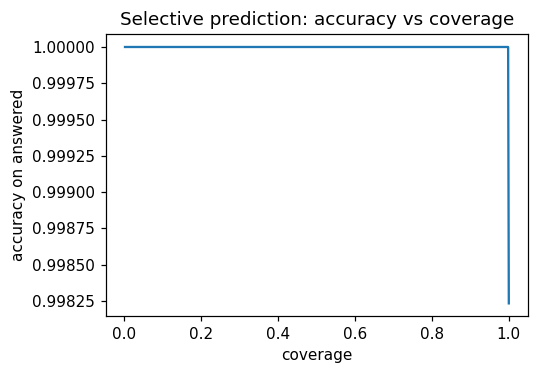

  coverage 100%: accuracy 0.998
  coverage 90%: accuracy 1.000
  coverage 80%: accuracy 1.000

Policy: abstain below confidence 0.700


In [ ]:
# generate OOD images (no external download needed)
rng_ood = np.random.default_rng(1)
ood_imgs, ood_tags = [], []

for _ in range(50):
    ood_imgs.append(
        np.full((IMG, IMG, 3), rng_ood.integers(0, 255, 3), np.uint8)
    )
    ood_tags.append("solid")
    ood_imgs.append(
        np.clip(
            rng_ood.normal(128, 50, (IMG, IMG, 3)), 0, 255,
        ).astype(np.uint8)
    )
    ood_tags.append("noise")

OOD_IMGS = np.stack(ood_imgs)
OOD_TAG = np.array(ood_tags)

# confidence scores
L_ood = predict(model, OOD_IMGS)
L_te = L0[idx_te]

conf_id = softmax(L_te, TEMP).max(1)
conf_ood = softmax(L_ood, TEMP).max(1)

# AUROC
y_true = np.r_[np.ones(len(conf_id)), np.zeros(len(conf_ood))]
scores = np.r_[conf_id, conf_ood]
auroc = roc_auc_score(y_true, scores)

print(f"OOD detection AUROC (MSP): {auroc:.3f}")
print(f"Mean confidence -- in-dist: {conf_id.mean():.3f} | OOD: {conf_ood.mean():.3f}")

# risk-coverage curve
def risk_coverage(P, y, order_score):
    o = np.argsort(-order_score)
    pred_rc = P.argmax(1)[o]
    yy = y[o]
    cov = np.arange(1, len(y) + 1) / len(y)
    acc = np.cumsum(pred_rc == yy) / np.arange(1, len(y) + 1)
    return cov, acc


P_te = P0[idx_te]
cov, acc_c = risk_coverage(P_te, yt, P_te.max(1))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(cov, acc_c)
ax.set_xlabel("coverage")
ax.set_ylabel("accuracy on answered")
ax.set_title("Selective prediction: accuracy vs coverage")
plt.tight_layout()
plt.show()

for c_ in [1.0, 0.9, 0.8]:
    k = int(c_ * len(yt)) - 1
    print(f"  coverage {c_:.0%}: accuracy {acc_c[k]:.3f}")

CONF_THR = float(np.percentile(P0[idx_va].max(1), 10)) if np.percentile(P0[idx_va].max(1), 10) < 0.99 else 0.7
print(f"\nPolicy: abstain below confidence {CONF_THR:.3f}")


---
## 12. Actionability (Criterion 6)

The rubric asks: does the explanation tell the affected person something they can **act on**?

For image classification, the farmer can't change the disease. But the **officer** can act on the explanation in specific ways. We split the system's outputs into actionable vs non-actionable:

| Output | Actionable? | What the officer does |
|---|---|---|
| Grad-CAM region highlights a dark spot | Yes | Check that specific leaf region during inspection |
| Triage tier = High | Yes | Prioritise this farm for immediate visit |
| Triage tier = Low | Yes | Schedule routine visit, don't rush |
| Confidence below threshold | Yes | Request a clearer photo or send to expert |
| OOD rejection | Yes | Ask farmer to retake with a proper leaf photo |
| The predicted disease name | Partly | Guides what treatment to prepare, but officer should verify |

**Counterfactual framing:** the deletion curve (§8) already answers the counterfactual question — "if I remove the region the model highlighted, does the prediction change?" We reframe that result here as advice to the officer.


Counterfactual examples: what if the highlighted region were absent?



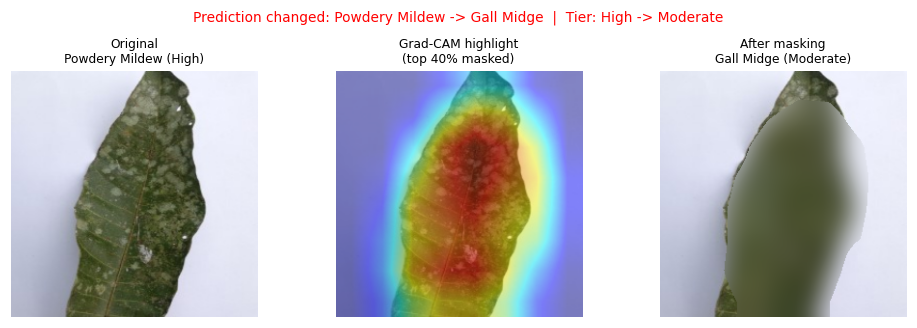

  {'original': 'Powdery Mildew', 'masked': 'Gall Midge', 'changed': True, 'conf_drop': 0.26085442304611206}



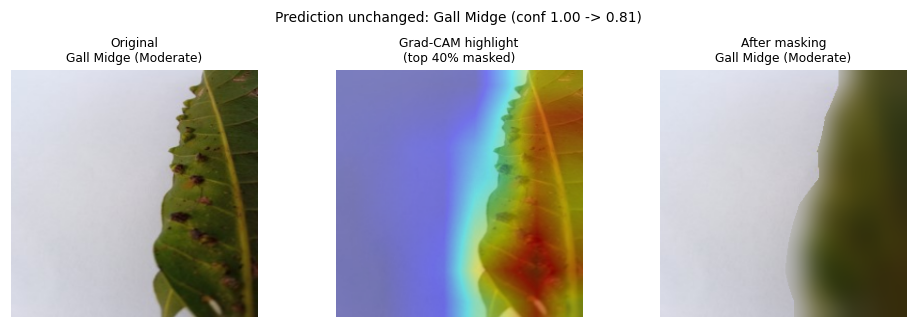

  {'original': 'Gall Midge', 'masked': 'Gall Midge', 'changed': False, 'conf_drop': 0.18881601095199585}



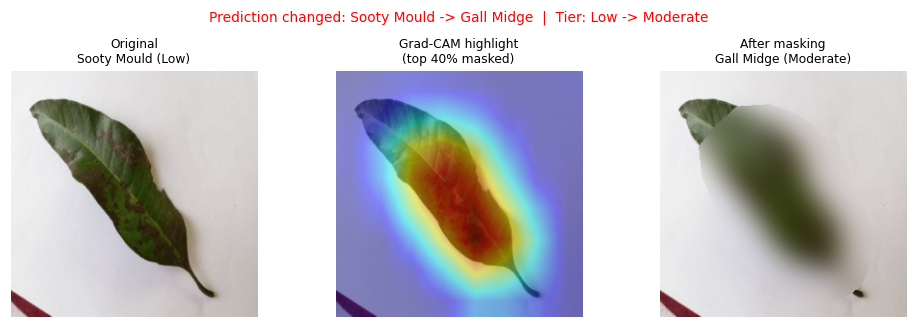

  {'original': 'Sooty Mould', 'masked': 'Gall Midge', 'changed': True, 'conf_drop': 0.10359704494476318}



In [ ]:
# ----- Actionability: counterfactual for the officer -----
# "What would change the model's prediction?"
# We use the deletion curve logic: mask the top-highlighted region and check

def counterfactual_example(img_idx, frac=0.4):
    """Show what happens if the highlighted region is removed."""
    img = IMGS[img_idx]
    cam = get_gradcam_maps(model, img[None])[0]

    # mask top-frac% of Grad-CAM highlighted pixels with blur
    order = np.argsort(-cam, axis=None)
    mask = np.zeros(cam.size, bool)
    mask[order[:int(frac * cam.size)]] = True
    mask = mask.reshape(cam.shape)

    blurred = cv2.GaussianBlur(img, (0, 0), 14)
    img_masked = img.copy()
    img_masked[mask] = blurred[mask]

    # predict on original vs masked
    L_orig = predict(model, img[None])
    L_masked = predict(model, img_masked[None])
    P_orig = softmax(L_orig, TEMP)[0]
    P_masked = softmax(L_masked, TEMP)[0]

    cls_orig = CLASSES[P_orig.argmax()]
    cls_masked = CLASSES[P_masked.argmax()]
    tier_orig = TRIAGE[cls_orig]
    tier_masked = TRIAGE[cls_masked]

    fig, axs = plt.subplots(1, 3, figsize=(9, 3))
    axs[0].imshow(img)
    axs[0].set_title(f"Original\n{cls_orig} ({tier_orig})", fontsize=8)
    axs[1].imshow(overlay(img, cam))
    axs[1].set_title(f"Grad-CAM highlight\n(top {frac:.0%} masked)", fontsize=8)
    axs[2].imshow(img_masked)
    axs[2].set_title(f"After masking\n{cls_masked} ({tier_masked})", fontsize=8)
    for a in axs:
        a.axis("off")

    changed = cls_orig != cls_masked
    if changed:
        plt.suptitle(
            f"Prediction changed: {cls_orig} -> {cls_masked}  |  "
            f"Tier: {tier_orig} -> {tier_masked}",
            fontsize=9, color="red",
        )
    else:
        plt.suptitle(
            f"Prediction unchanged: {cls_orig} (conf {P_orig.max():.2f} -> {P_masked.max():.2f})",
            fontsize=9,
        )
    plt.tight_layout()
    plt.show()

    return {
        "original": cls_orig,
        "masked": cls_masked,
        "changed": changed,
        "conf_drop": float(P_orig.max() - P_masked.max()),
    }


# run on a few test images from different tiers
print("Counterfactual examples: what if the highlighted region were absent?\n")
for tier_level in [3, 2, 1]:  # High, Moderate, Low
    pool = [
        i for i in idx_te
        if tv[Y[i]] == tier_level and L0[i].argmax() == Y[i]
    ]
    if pool:
        i = np.random.default_rng(99).choice(pool)
        result = counterfactual_example(i)
        print(f"  {result}\n")


---
## 13. Decision-support output (what the officer sees)


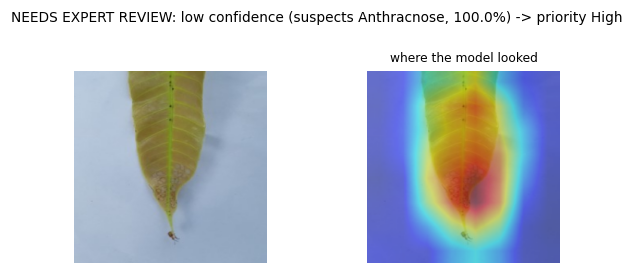

{'decision': 'NEEDS EXPERT REVIEW: low confidence (suspects Anthracnose, 100.0%)', 'tier': 'High', 'confidence': 0.9999978542327881}


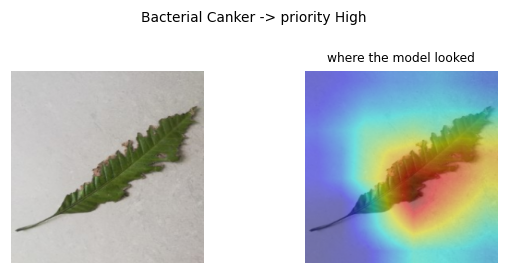

{'decision': 'Bacterial Canker', 'tier': 'High', 'confidence': 0.9999997615814209}


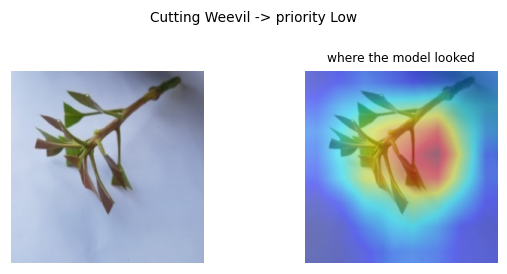

{'decision': 'Cutting Weevil', 'tier': 'Low', 'confidence': 1.0}


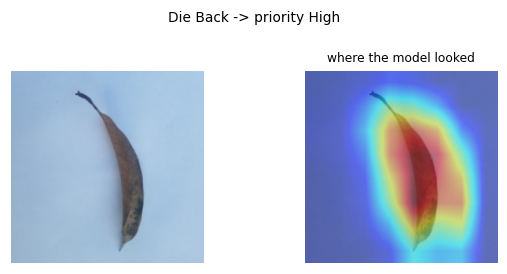

{'decision': 'Die Back', 'tier': 'High', 'confidence': 1.0}


In [ ]:
def triage_report(img_u8, show=True):
    """Full triage pipeline: predict, check confidence, show Grad-CAM."""
    L = predict(model, img_u8[None])
    P = softmax(L, TEMP)[0]
    conf = P.max()

    if conf < CONF_THR:
        c = int(P.argmax())
        suspect = CLASSES[c]
        decision = f"NEEDS EXPERT REVIEW: low confidence (suspects {suspect}, {conf:.1%})"
        tier = TRIAGE[suspect]
    else:
        c = int(P.argmax())
        decision = CLASSES[c]
        tier = TRIAGE[CLASSES[c]]

    if show:
        cam = get_gradcam_maps(model, img_u8[None])[0]
        fig, ax = plt.subplots(1, 2, figsize=(5.5, 2.5))
        ax[0].imshow(img_u8)
        ax[1].imshow(overlay(img_u8, cam))
        ax[1].set_title("where the model looked", fontsize=8)
        for a in ax:
            a.axis("off")
        title = decision + (f" -> priority {tier}" if tier else "")
        plt.suptitle(title, fontsize=9)
        plt.tight_layout()
        plt.show()

    return {"decision": decision, "tier": tier, "confidence": float(conf)}


# demo
for c in range(min(4, NC)):
    i = idx_te[np.where(Y[idx_te] == c)[0][0]]
    print(triage_report(IMGS[i]))


---
## 14. Ethics and data handling (Criterion 8)

### Data collection
The MangoLeafBD dataset (Ahmed et al., 2023) was collected from four mango orchards in Bangladesh: Sher-e-Bangla Agricultural University, Jahangirnagar University, and village orchards in Udaypur and Itakhola. It is publicly available on Kaggle under the CC BY 4.0 licence, which permits sharing and adaptation with attribution.

The images contain only mango leaves — no identifiable people, no personal data. No PII removal was necessary.

### Sensitive attributes and proxies
There are no protected attributes (race, gender, religion, etc.) in the dataset — the subjects are leaves, not people. However, there are **dataset-level biases** that function like proxies:

**Geographic bias:** all images come from four orchards in Bangladesh. Disease prevalence, leaf appearance, and lighting conditions are specific to this region. A model trained here may not generalise to orchards in Thailand, India, or elsewhere.

**Background as a proxy for class:** the background-shortcut analysis (§10) shows that photos of the same disease class were often taken on the same surface. Background colour correlates with the disease label — not because of biology, but because of how the photos were collected. This is the dataset's main bias, and the background-swap experiment quantifies its impact.

**Triage tier bias:** the triage mapping is expert judgement, not a learned quantity. It cannot encode a bias from the training data. However, the tier assignments are based on agronomic literature that may not reflect local conditions in every region. We report a sensitivity analysis (§5) to show that conclusions don't depend on a single triage table.

### Responsible deployment considerations
- The system is a **decision-support tool**, not an autonomous decision-maker. The officer always makes the final call.
- The scope statement (§13.3) lists exactly what the evidence supports and what it does not.
- The OOD rejection path (§11) prevents the system from giving confident answers on non-leaf inputs.
- Any deployment outside Bangladeshi orchards would require re-validation on local data.


---
## 15. Human assessment kit, related work, scope

### 15.1 Human evidence protocol (Criterion 5)

The rubric requires testing whether the explanation helps a **person**. We use a **single-group design with blind null controls**:

**Design:**
- All raters see the same 20 image pairs (leaf photo + heatmap overlay + predicted class)
- Every 4th image secretly has a **random heatmap** instead of real Grad-CAM (the rater does not know which)
- For each image, raters answer two questions:
  - "Does the highlighted area match a visible symptom?" (1–5)
  - "Would you trust this prediction enough to act on it?" (1–5)

**Materials:** the 20 exported image pairs in `human_study/images/`. The column `overlay_is_null` in the response sheet identifies which 5 cases are null controls — **hide this column from raters**.

**Sample:** 5 raters (classmates). Each rater evaluates all 20 images independently, without discussion.

**Analysis:**
- Separate ratings into real Grad-CAM (15 images × 5 raters = 75 ratings) vs null overlays (5 images × 5 raters = 25 ratings)
- Compare mean symptom-match and mean trust scores between the two groups
- If real Grad-CAM scores higher than null, the explanation adds value beyond just showing a colourful overlay

**What to report:**
- Mean scores for real vs null overlays
- Sample size — do not claim statistical significance at this scale
- 2–3 things people said out loud while working (the rubric specifically asks for this)

**Important:** low human agreement or no improvement is a valid finding. The rubric says "hiding the actual outcome is a failing grade" — report whatever you find.

In [ ]:
hdir = OUT / "human_study"
(hdir / "images").mkdir(parents=True, exist_ok=True)

rng_h = np.random.default_rng(77)
sel = []
for t in range(4):
    pool = [
        i for i in idx_te
        if tv[Y[i]] == t and L0[i].argmax() == Y[i]
    ]
    if pool:
        sel += list(rng_h.choice(
            pool,
            min(3 if QUICK_MODE else 5, len(pool)),
            replace=False,
        ))

sel_cams = get_gradcam_maps(model, IMGS[np.array(sel)])
items = []

for k, i in enumerate(sel):
    is_null = (k % 4 == 3)
    cam = null_random(np.random.default_rng(k)) if is_null else sel_cams[k]
    fn = f"case_{k:02d}.png"
    both = np.concatenate([IMGS[i], overlay(IMGS[i], cam)], axis=1)
    cv2.imwrite(
        str(hdir / "images" / fn),
        cv2.cvtColor(both, cv2.COLOR_RGB2BGR),
    )
    items.append({
        "case": fn,
        "predicted": CLASSES[L0[i].argmax()],
        "tier": TRIAGE[CLASSES[L0[i].argmax()]],
        "overlay_is_null": is_null,
        "rater_id": "",
        "symptom_match_1to5": "",
        "trust_1to5": "",
    })

pd.DataFrame(items).to_csv(
    hdir / "response_sheet_TEMPLATE.csv", index=False,
)
print(f"{len(items)} cases exported to {hdir}")
print("(hide the overlay_is_null column from raters)")


20 cases exported to /content/drive/MyDrive/XDS/mango_outputs/human_study
(hide the overlay_is_null column from raters)


### 15.2 Related work to add

Saliency in plant disease is not new. The contribution is the **systematic evaluation of explanation quality for a triage decision**. Key references:

- Brahimi et al. (2017) -- saliency-map symptom visualisation for tomato disease
- Toda & Okura (2019) -- visualising what CNNs detect in plant disease
- Adebayo et al. (2018) -- Sanity Checks for Saliency Maps
- Petsiuk et al. (2018) -- RISE deletion/insertion evaluation
- Selvaraju et al. (2017) -- Grad-CAM

### 15.3 Scope statement

| Claim | Supported by | Caveat |
|---|---|---|
| Accuracy on MangoLeafBD | grouped split, per-class metrics | four Bangladeshi orchards only |
| Explanation is faithful | deletion/insertion + randomisation sanity check | blur baseline; only Grad-CAM tested |
| Explanation is on lesions | proxy + annotation kit | proxy invalid for Healthy/Die Back/Cutting Weevil |
| Works on farmer photos | simulated stress test | no real field images |
| Handles non-leaf input | OOD test with synthetic images | not tested on other plants' leaves |


---
## 16. Model card (Criterion 9)

**Model name:** ResNet-50 fine-tuned for mango leaf disease classification

**Intended use:** Decision-support for agricultural field officers triaging farmer-submitted leaf photos. Not intended as an autonomous diagnostic tool.

**Training data:** MangoLeafBD (Ahmed et al., 2023) — 4,000 images from four orchards in Bangladesh, 8 classes (7 diseases + healthy), 500 images per class. ~1,800 distinct leaves; remainder are zoom/rotation augmentations. Grouped stratified split ensures no leaf appears in both train and test.

**Architecture:** ResNet-50 (25.6M parameters, 50 layers), fine-tuned from ImageNet weights. Backbone LR 1e-4, head LR 1e-3, AdamW, one-cycle schedule, label smoothing 0.1, 12 epochs, best checkpoint by validation macro-F1.

**Evaluation results:** (reported on grouped test set)
- Test accuracy and macro-F1: see `table_classification_comparison.csv`
- Triage-level missed-high rate: see §5
- Faithfulness (deletion/insertion AUC vs null explainers): see `table_faithfulness_auc.csv`
- Stability across seeds and perturbations: see `table_stability_perturbations.csv`

**Explanation method:** Grad-CAM on the last convolutional block (layer4). Evaluated for faithfulness (deletion/insertion curves, cascading randomisation), plausibility (lesion enrichment, pointing game), and stability (cross-seed, cross-perturbation).

**Known limitations:**
- Trained on four Bangladeshi orchards only — not validated on other regions, cultivars, or imaging conditions
- Lesion proxy uses simple dark-pixel thresholds — invalid for Healthy, Die Back, Cutting Weevil, Powdery Mildew
- OOD detection tested on synthetic images only — not tested on other plants' leaves
- Simulated field shift, not real farmer photos
- Triage tiers are expert judgement; some supporting sources are websites rather than peer-reviewed literature
- CuDNN determinism is set, but cross-hardware reproducibility is not guaranteed

**Random seeds:** see the seed registry in the config cell. All seeds are fixed; `REUSE_CKPT=True` ensures re-runs use saved checkpoints.

**Licence:** code is MIT; dataset is CC BY 4.0 (Ahmed et al., 2023).


In [ ]:
# save key tables for the report
for name, obj in [
    ("classification_comparison", cmp_df),
    ("faithfulness_auc", fa),
    ("stability_perturbations", st_pert),
    ("field_shift", field_df),
]:
    obj.to_csv(OUT / f"table_{name}.csv")

print("Tables saved to", OUT)


Tables saved to /content/drive/MyDrive/XDS/mango_outputs


## 17. Inference

Saving Screenshot 2026-11-09 011021.png to Screenshot 2026-11-09 011021.png

--- Screenshot 2026-11-09 011021.png ---


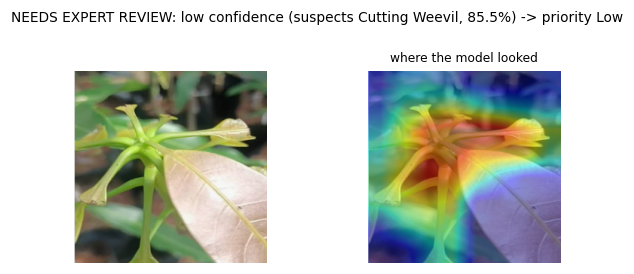

{'decision': 'NEEDS EXPERT REVIEW: low confidence (suspects Cutting Weevil, 85.5%)', 'tier': 'Low', 'confidence': 0.8545418381690979}


In [ ]:
# upload a photo from your computer
from google.colab import files
uploaded = files.upload()  # click "Choose Files" and pick a leaf photo

# load and run
for fname in uploaded:
    img = cv2.resize(
        cv2.cvtColor(cv2.imread(fname), cv2.COLOR_BGR2RGB),
        (IMG, IMG),
    )
    print(f"\n--- {fname} ---")
    result = triage_report(img)
    print(result)

Saving Screenshot 2026-11-09 011329.png to Screenshot 2026-11-09 011329.png

--- Screenshot 2026-11-09 011329.png ---


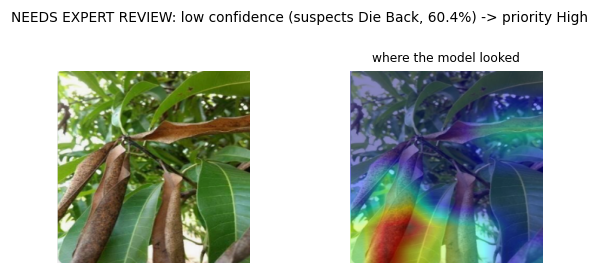

{'decision': 'NEEDS EXPERT REVIEW: low confidence (suspects Die Back, 60.4%)', 'tier': 'High', 'confidence': 0.6042296886444092}


In [ ]:
# upload a photo from your computer
from google.colab import files
uploaded = files.upload()  # click "Choose Files" and pick a leaf photo

# load and run
for fname in uploaded:
    img = cv2.resize(
        cv2.cvtColor(cv2.imread(fname), cv2.COLOR_BGR2RGB),
        (IMG, IMG),
    )
    print(f"\n--- {fname} ---")
    result = triage_report(img)
    print(result)

Saving a-green-mango-leaf-isolated-on-a-white-background-mango-leaves-have-many-health-benefits-such-as-maintaining-healthy-skin-lowering-blood-pressure-and-treating-diarrhea-photo.jpg to a-green-mango-leaf-isolated-on-a-white-background-mango-leaves-have-many-health-benefits-such-as-maintaining-healthy-skin-lowering-blood-pressure-and-treating-diarrhea-photo (1).jpg

--- a-green-mango-leaf-isolated-on-a-white-background-mango-leaves-have-many-health-benefits-such-as-maintaining-healthy-skin-lowering-blood-pressure-and-treating-diarrhea-photo (1).jpg ---


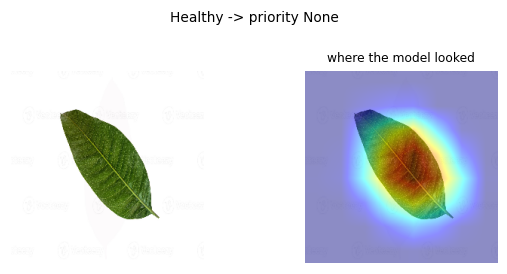

{'decision': 'Healthy', 'tier': 'None', 'confidence': 0.9999936819076538}


In [ ]:
# upload a photo from your computer
from google.colab import files
uploaded = files.upload()  # click "Choose Files" and pick a leaf photo

# load and run
for fname in uploaded:
    img = cv2.resize(
        cv2.cvtColor(cv2.imread(fname), cv2.COLOR_BGR2RGB),
        (IMG, IMG),
    )
    print(f"\n--- {fname} ---")
    result = triage_report(img)
    print(result)

Saving Anthracnose-symptoms-on-mango-leaves-Left-mature-leaf-with-old-lesions-Right-young.webp to Anthracnose-symptoms-on-mango-leaves-Left-mature-leaf-with-old-lesions-Right-young.webp

--- Anthracnose-symptoms-on-mango-leaves-Left-mature-leaf-with-old-lesions-Right-young.webp ---


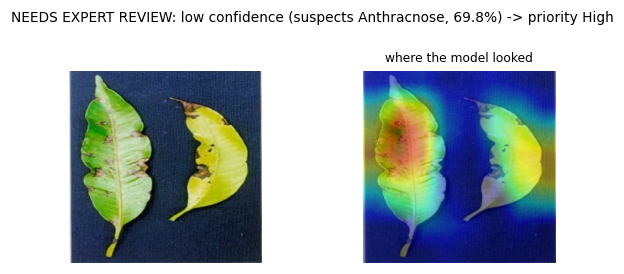

{'decision': 'NEEDS EXPERT REVIEW: low confidence (suspects Anthracnose, 69.8%)', 'tier': 'High', 'confidence': 0.6978625655174255}


In [ ]:
# upload a photo from your computer
from google.colab import files
uploaded = files.upload()  # click "Choose Files" and pick a leaf photo

# load and run
for fname in uploaded:
    img = cv2.resize(
        cv2.cvtColor(cv2.imread(fname), cv2.COLOR_BGR2RGB),
        (IMG, IMG),
    )
    print(f"\n--- {fname} ---")
    result = triage_report(img)
    print(result)